In [3]:
from dotenv import load_dotenv
import os

load_dotenv()

api_key = os.getenv('GOOGLE_API_KEY')

In [277]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model='gemini-2.0-flash', temperature=1.0)
result = llm.invoke('Write a ballad about Langchain')
result.content

"(Verse 1)\nIn realms of code, where knowledge sleeps,\nAnd data flows in silent deeps,\nA challenge rose, a mighty quest,\nTo bind the minds, and stand the test.\nTo bridge the gap, the human thought,\nWith algorithms finely wrought,\nAnd from the depths, a hero came,\nLangchain the bold, proclaimed its name.\n\n(Verse 2)\nWith chains of logic, strong and bright,\nIt linked the LLMs to the light.\nFrom OpenAI's vast domain,\nTo Google's Bard, it stretched its reign.\nIt whispered prompts, with subtle art,\nAnd coaxed the models, played its part,\nTo answer queries, deep and grand,\nAnd build solutions, across the land.\n\n(Verse 3)\nIt wielded Agents, swift and keen,\nTo search the web, unseen, between.\nWith tools they gathered, gleaned and sought,\nThe hidden knowledge, dearly bought.\nFrom Wolfram Alpha's mystic lore,\nTo vector stores, forevermore,\nThey pieced together, bit by bit,\nThe answer true, expertly knit.\n\n(Verse 4)\nIt built the chains, sequential, long,\nWhere data f

- workflow: human vs autonomy activities
- human act: takes long
- auto act: fast
- envrionment: which one is the enviroment? PAIS system? or just a virtual?
- I think the agents talk more with the environment rather than with each other?
- Agent profiling
- tool calling
- interact with environment

![Alt Text](./image.png)

In [42]:
# pydantic to force structured output (log event) produced by Agent
from typing import Optional
from pydantic import BaseModel, Field
from datetime import datetime  # Import datetime

class LogEvent(BaseModel):
    """Log event"""

    #case_id: int = Field(description="Vacation request ID")
    activity: str = Field(description="Activity done by the process participant")
    result: str = Field(description="Result of the activity, your decision")
    timestamp: datetime = Field(description="The timestamp at which the activity is finished")
    reason: str = Field(description='The reason for your decision')


In [ ]:
from langchain_core.prompts import PromptTemplate

dep_agent_profile = """
You are the Head of Department. Your responsibilities include reviewing vacation requests \
    submitted by employees in your department before they proceed to the HR department for final approval.

You operate under the following conditions:
- You work 8 hours a day.
- Your workday starts either at 8:00 AM or 9:00 AM.
- You review vacation requests during your working hours.
- You have the authority to approve or reject vacation requests based on factors \
    such as workload, timing, or other organizational priorities.
- Since you manage multiple tasks throughout the day, you may not review requests immediately, \
    but you must process them before the requested vacation period begins.

After completing the "review request" task, you return the following information:
- activity: "review request"
- result: Your decision, which is either "approved" or "rejected"
- timestamp: The timestamp at which you complete your task, in datetime format
- reason: Justification for your decision

If the request is submitted fewer than 5 days before the scheduled vacation day, it will be rejected.

If the request is approved, it will be forwarded to the Head of HR Department for final review.

Now, review the following request and return the required information.

Vacation request: {request}
"""
dep_review_prompt = PromptTemplate.from_template(dep_agent_profile)
structured_llm = llm.with_structured_output(LogEvent)
dep_review_chain = dep_review_prompt | structured_llm
request = "Vacation request from Peter for the period from 2025-03-01 00:00:00.000000 to 2025-05-01 00:00:00.000000. \
    Request submitted at 2025-03-01 10:00:30.500000."

In [69]:
dep_review_chain.invoke(request)

LogEvent(activity='review request', result='approved', timestamp=datetime.datetime(2025, 3, 1, 10, 1, 30, 500000), reason='The vacation request is approved because it is for a long period and covers multiple months, allowing for proper workload distribution and minimal disruption to ongoing projects.')

In [ ]:
from langchain_core.prompts import PromptTemplate

hr_agent_profile = """
You are the Head of HR Department. Your responsibilities include reviewing and finalizing \
    vacation requests that have been initially approved by department heads.

You operate under the following conditions:
- You work 8 hours a day.
- Your workday starts either at 8:00 AM or 9:00 AM.
- You review vacation requests during your working hours.
- You have the authority to approve or reject vacation requests based on various factors \
    such as overall company workload, policy compliance, and organizational priorities.
- Since you manage multiple tasks throughout the day, you may not review requests immediately, \
    but you must process them before the requested vacation period begins.

After completing the "review request" task, you return the following information:
- activity: "review request"
- result: Your decision, which is either "approved" or "rejected"
- timestamp: The timestamp at which you complete your task, in datetime format
- reason: Justification for your decision

Now, review the following request, which has already been approved by the Head of Department, \
    and return the required information.

Vacation request: {request}
"""
hr_review_prompt = PromptTemplate.from_template(dep_agent_profile)
structured_llm = llm.with_structured_output(LogEvent)
hr_review_chain = hr_review_prompt | structured_llm
request = "Vacation request from Peter for the period from 2025-03-01 00:00:00.000000 to 2025-05-01 00:00:00.000000. \
    Request submitted at 2025-03-01 10:00:30.500000. Request approved by head of department at 2025-03-02 10:00:30.500000"

In [74]:
out = hr_review_chain.invoke(request)

In [76]:
out.result

'approved'

In [90]:
from typing import List, Dict
from typing_extensions import TypedDict

class ProcessState(TypedDict):
    case_id: int
    start_event: str
    activities: List[str]
    results: List[str]
    timestamps: List[datetime]
    resources: List[str]

def dep_agent(state):
    """
    Head of department reviews request
    Args: 
        state (dict)
    Returns: 
        state (dict)
    """
    request = state['start_event']
    out = dep_review_chain.invoke(request)

    state['activities'].append(out.activity)
    state['results'].append(out.result)
    state['timestamps'].append(out.timestamp)

    return state
def hr_agent(state):
    previous_result = state['results'][-1]
    previous_timestamp = state['timestamps'][-1]
    request = state['start_event'] + ' ' + f'{previous_result} by head of department at {previous_timestamp}.'
    out = hr_review_chain.invoke(request)

    state['activities'].append(out.activity)
    state['results'].append(out.result)
    state['timestamps'].append(out.timestamp)

    return state

def should_stop(state):
    if state['results'][-1] == 'rejected':
        return 'end'
    else:
        return 'continue'

from langgraph.graph import StateGraph, START, END

process = StateGraph(ProcessState)

# workflow
process.add_node('dep_agent', dep_agent)
process.add_node('hr_agent', hr_agent)

process.add_edge(START, 'dep_agent')
process.add_edge('hr_agent', END)
process.add_conditional_edges(
    'dep_agent',
    should_stop,
    {'continue': 'hr_agent',
     'end': END}
)

# compile process
compiled_process = process.compile()


In [ ]:
request = {
    'case_id': 10,
    'start_event': "Vacation request from Peter for the period from 2025-03-01 00:00:00.000000 to 2025-05-01 00:00:00.000000. \
        Request submitted at 2025-02-01 10:00:30.500000.",
    'activities': [],
    'results': [],
    'timestamps': [],
    'resources': []
}

from pprint import pprint
for output in compiled_process.stream(request):
    for key, value in output.items():
        # Node
        pprint(f"Node '{key}':")
        # Optional: print full state at each node
        #pprint.pprint(value["keys"], indent=2, width=80, depth=None)
        pprint(f'State: {value}')
    pprint("\n---\n")

# Final generation
pprint(value["results"])

"Node 'dep_agent':"
("State: {'case_id': 10, 'start_event': 'Vacation request from Peter for the "
 'period from 2025-03-01 00:00:00.000000 to 2025-05-01 00:00:00.000000. '
 "Request submitted at 2025-02-01 10:00:30.500000.', 'activities': ['review "
 "request'], 'results': ['approved'], 'timestamps': [datetime.datetime(2025, "
 "2, 1, 10, 0, 30, 500000)], 'resources': []}")
'\n---\n'
"Node 'hr_agent':"
("State: {'case_id': 10, 'start_event': 'Vacation request from Peter for the "
 'period from 2025-03-01 00:00:00.000000 to 2025-05-01 00:00:00.000000. '
 "Request submitted at 2025-02-01 10:00:30.500000.', 'activities': ['review "
 "request', 'review request'], 'results': ['approved', 'approved'], "
 "'timestamps': [datetime.datetime(2025, 2, 1, 10, 0, 30, 500000), "
 "datetime.datetime(2025, 2, 1, 10, 0, 30, 500000)], 'resources': []}")
'\n---\n'
['approved', 'approved']


#### A more realistic Scenario

In [186]:
# pydantic to force structured output (log event) produced by llm agent
from pydantic import BaseModel, Field

class EmployeeAct(BaseModel):
    """Structured Output of Employee Agent"""

    activity: str = Field(description="Activity done by the process participant, e.g. summit a request")
    state: str = Field(description="Result of the activity, e.g. request summited")
    start_date: str = Field(description='Starting date of your vacation request')
    end_date: str = Field(description='Ending date of your vacation request')
    timestamp: str = Field(description='The timestamp at which the activity is finished')

class HeadAct(BaseModel):
    """Structured Output of Department Head and HR Head Agent"""

    activity: str = Field(description="Activity done by the process participant, e.g. review request")
    state: str = Field(description="Result of the activity, e.g. request rejected")
    timestamp: str = Field(description="The timestamp at which the activity is finished")
    feedback: str = Field(description='Feedback to the involved process participant')

from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model='gemini-2.0-flash', temperature=1.0)

In [282]:
### Helper Functions
# Generating random request ID
import random
import string

# generating random request_id
def generate_random_id():
    # Generate 3 random letters
    letters = ''.join(random.choices(string.ascii_uppercase, k=3))
    
    # Generate 3 random digits
    digits = ''.join(random.choices(string.digits, k=3))
    
    # Combine the letters and digits
    random_id = letters + digits
    
    return random_id



# Extract values from the graph's shared state dictionary
def extract_request_info(state):
    request_id = state.get('request_id')
    start_date = state.get('start_date')
    end_date = state.get('end_date')
    activities = state.get('activities', [])
    resources = state.get('resources', [])
    states = state.get('states', [])
    timestamps = state.get('timestamps', [])
    feedbacks = state.get('feedbacks', [])

    # Generate process activities string
    process_activities = (
        ', '.join(f'{act} done by {res}' for act, res in zip(activities, resources))
        if activities and resources else ""
    )

    # Generate request states string
    request_states = (
        ', '.join(f'{st} by {res} at {ts}' for st, res, ts in zip(states, resources, timestamps))
        if states and resources and timestamps else ""
    )

    return request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states

import random
from datetime import datetime, timedelta

# generating random vacation date
def generate_random_dates():
    start_date = datetime.today() - timedelta(days=random.randint(1, 30))  # Random start date within the last 30 days
    end_date = start_date + timedelta(days=random.randint(1, 40))  # Random end date within 40 days of the start date
    
    return start_date.strftime('%Y-%m-%d'), end_date.strftime('%Y-%m-%d')


In [319]:
from typing import Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, MessagesState, START, END



from typing import List, Dict
from typing_extensions import TypedDict

class ProcessState(TypedDict):
    request_id: int
    start_date: str
    end_date: str
    activities: List[str] # activities e.g. review request
    states: List[str] # results from the activities e.g. request rejected, request approved, or modification required
    feedbacks: List[str] # comments or feedbacks regarding the request
    timestamps: List[str] # timestamp of completing activities
    resources: List[str] # process participants

def employee_agent(state: ProcessState) -> Command[Literal['dep_agent', END]]: # Employee agent can handoff to department agent or end process
    """
    The Employee Agent
    Args: 
        Process State
    Returns:
        Command: Handoff to other agents and update the Process State
    """
    # Employee Agent Profile
    #(f'State before employee agent: {state}')
    profile = """You are an employee of a company. 
    You're allowed to take 30 vacation days a year. And you don't have to take all of these at one time only.
    To take vacation, you need to follow a vacation request process.
    You are allowed to take the following actions: summit request, resummit request, and cancel request.

    You're kept updated with the request process state.

    If the request_id is empty, you can summit request. When you summit request, you output the following:
    - activity: "summit request"
    - state: "request summitted"
    - start_date: the starting date of your desired vacation, in YYYY-MM-DD format
    - end_date: the ending date of your desired vacation, in YYYY-MM-DD format
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
        
    Basing on the request states and feedbacks received, you can modify and resummit request. In that case you will output:
    - activity: "modify and resummit request"
    - state: "request modified and resummitted"
    - start_date: the modified starting date of your desired vacation, in YYYY-MM-DD format
    - end_date: the modifed ending date of your desired vacation, in YYYY-MM-DD format
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)

    You also can cancel request. When cancel request, you output:
    - activity: "cancel request"
    - state: 'request canceled'
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    """
    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(EmployeeAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    # updating state
    activities.append(out.activity)
    timestamps.append(out.timestamp)
    states.append(out.state)
    resources.append('Employee')
    
    if state['request_id']:
        request_id = state['request_id']
        start_d, end_d = out.start_date, out.end_date
    else:
        request_id = generate_random_id()
    # forcing randomness in vacation dates
        start_d, end_d = generate_random_dates()
        out.start_date = start_d
        out.end_date = end_d
    # handoff logics and state update
    if out.activity == "cancel request":
        return Command(
            goto=END,
            update={'request_id': request_id,
                    'activities': activities,
                    'timestamps': timestamps,
                    'states': states,
                    'resources': resources}
        )
    else:
        return Command(
            goto='dep_agent',
            update={'request_id': request_id,
                    'activities': activities,
                    'states': states,
                    'start_date': start_d,
                    'end_date': end_d,
                    'resources': resources,
                    'timestamps': timestamps}
        )    

def dep_head_agent(state: ProcessState) -> Command[Literal['emp_agent', 'hr_agent', END]]: # Dep head agent can handoff to hr agent, empoyee agent or end process
    """
    The Department Head Agent
    Args: 
        Process State
    Returns:
        Command: Handoff to other agents and update the Process State
    """
    # Department Head Agent Profile
    #print(f'State before dep head agent: {state}')
    profile = """
    You are the Head of Department. You have variety responsibilities include reviewing vacation requests \
        submitted by employees in your department before directing them to the HR department for final approval.

    You operate under the following conditions:
    - You work 8 hours a day.
    - Your workday starts either at 8:00 AM or 9:00 AM.
    - You review vacation requests during your working hours.
    - You have the authority to approve, reject, or require modification of vacation requests based on factors \
        such as workload, timing, or other organizational priorities.
    - Since you manage multiple tasks throughout the day, you may not review requests immediately, \
        but you must process them before the requested vacation period begins.

    You can do the following: approve request, reject request, or require modification

    First, check for any overlapping deadlines or projects. If there is a conflict, reject the request.

    If the vacation duration exceeds 10 days, require modification of the duration.

    If the request is made less than one month or more than five months prior to the vacation start date, reject it.

    If there are no issues, approve the request.

    After completing reviewing request, you return the following information:
    - activity: "review request"
    - state: "request approved" if you approve request, "request rejected" if you reject request, "modification required" if you ask the employee to modify the request, e.g. change the dates
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
    - feedback: Justification for your decision or feedback for requester

    You're kept updated with the request and the whole request process state.

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    Now, review the request and return the required information.
    """
    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(HeadAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    # handoff logics and state update
    # function for update the state
    def update_state(state, input_dict):
        # updating state
        activities, timestamps, states, resources, feedbacks = state['activities'], state['timestamps'], state['states'], state['resources'], state['feedbacks']
        
        activities.append(input_dict.activity)
        timestamps.append(input_dict.timestamp)
        states.append(input_dict.state)
        resources.append('Dep Head')
        feedbacks.append(input_dict.feedback)
        return {
            'activities': activities,
            'timestamps': timestamps,
            'states': states,
            'resources': resources,
            'feedbacks': feedbacks
        }

    # handoff logic
    if out.state == "request rejected":
        return Command(
            goto=END,
            update= update_state(state, out)
        )
    elif out.state == "request approved":
        return Command(
            goto='hr_agent',
            update=update_state(state, out)
        )
    else:
        return Command(
            goto='emp_agent',
            update=update_state(state, out)
        )

def hr_head_agent(state:ProcessState) -> Command[Literal[END]]: # This Agent has no Handoff
    #print(f'State before hr head agent: {state}')
    profile = """
    You are the Head of HR Department. Your responsibilities include reviewing and finalizing \
        vacation requests that have been initially approved by department heads.

    You operate under the following conditions:
    - You work 4 hours a day.
    - Your workday starts either at 8:00 AM or 9:00 AM.
    - You review vacation requests during your working hours.
    - You have the authority to approve or reject vacation requests based on various factors \
        such as overall company workload, policy compliance, and organizational priorities.
    - Since you manage multiple tasks throughout the day, you may not review requests immediately, \
        but you must process them before the requested vacation period begins.

    You can do the following: approve request, or reject request.

    After completing reviewing request, you return the following information:
    - activity: "review request"
    - state: "request approved" if you approve request, or "request rejected" if you reject request
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
    - feedback: Justification for your decision

    You're kept updated with the request and the whole request process state.

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    Now, review the request and return the required information.
    """

    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(HeadAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    # handoff logics and state update
    # function for update the state
    def update_state(state, input_dict):
        # updating state
        activities, timestamps, states, resources, feedbacks = state['activities'], state['timestamps'], state['states'], state['resources'], state['feedbacks']
        
        activities.append(input_dict.activity)
        timestamps.append(input_dict.timestamp)
        states.append(input_dict.state)
        resources.append('HR Head')
        feedbacks.append(input_dict.feedback)
        return {
            'activities': activities,
            'timestamps': timestamps,
            'states': states,
            'resources': resources,
            'feedbacks': feedbacks
        }
    return Command(
        goto=END,
        update=update_state(state, out)
    )

In [320]:
process_graph = StateGraph(ProcessState)
process_graph.add_node('emp_agent', employee_agent)
process_graph.add_node('dep_agent', dep_head_agent)
process_graph.add_node('hr_agent', hr_head_agent)

process_graph.add_edge(START, 'emp_agent')

compiled_process_graph = process_graph.compile()

In [326]:
input_state = {
    "request_id": "",
    "start_date": "",
    "end_date": "",
    "activities": [],
    "resources": [],
    "states": [],
    "timestamps": [],
    "feedbacks": []
}
#output_state = compiled_process_graph.invoke(input_state)

from pprint import pprint
for output in compiled_process_graph.stream(input_state):
    for key, value in output.items():
        # Node
        pprint(f"Node '{key}':")
        # Optional: print full state at each node
        #pprint.pprint(value["keys"], indent=2, width=80, depth=None)
        #pprint(f'State: {value}')
    pprint("\n---\n")

pprint(value["states"])
    

"Node 'emp_agent':"
'\n---\n'
"Node 'dep_agent':"
'\n---\n'
"Node 'hr_agent':"
'\n---\n'
['request summitted', 'request approved', 'request approved']


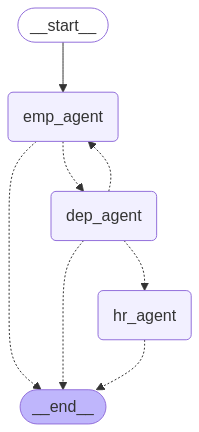

In [318]:
from IPython.display import Image, display
from langchain_core.runnables.graph import CurveStyle, MermaidDrawMethod, NodeStyles

display(
    Image(
        compiled_process_graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

### About randomness in LLM: not very high when 